# NB11: Discrete Exterior Calculus & Conservation Audit

This notebook distinguishes dependency-graph algebra from physical conservation.
An incidence matrix built from Functor dependencies is an illustrative graph
operator; it is not a physical mesh/stoichiometric operator or a conservation
certificate. Physical budgets below are checked from actual process outputs.

**Core concepts:**
1. Incidence matrix $\mathbf{B}$ from the dependency graph
2. Structural conservation via Theorem 3.1
3. Cycle rank (Betti number) $\beta_1 = m - n + \kappa$ via Theorem 3.2
4. Noether invariant drift from the left null space of $\mathbf{B}$
5. Actual decomposition budgets and StateManager clipping diagnostics

**References:**
- RELIC Coertheory Document, Sections 2.5 and 3.1--3.3
- Manzoni & Porporato (2009), Soil Biology and Biochemistry
- Noether (1918), Invariante Variationsprobleme

## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
All computations below are intended to use actual RELIC functors, the actual simulator or orchestration layer, and real validation pathways rather than notebook-defined pseudo-process equations.


In [1]:
# ---------------------------------------------------------------
# References:
# RELIC architecture overview for dependency graphs and validation flow
# Hyman et al. style DEC notation for incidence operators in process graphs
# Mathematical expression:
# B in {-1, 0, +1}^{n_nodes x n_edges}
# beta_1 = |E| - |V| + beta_0
# Parameter meanings:
# PROJECT_ROOT: RELIC repository root directory
# OMP_NUM_THREADS: thread cap for stable notebook execution
# ---------------------------------------------------------------

import os
import sys
import warnings
from pathlib import Path

os.environ['OMP_NUM_THREADS'] = '1'
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
warnings.filterwarnings('ignore', message=r'The pynvml package is deprecated.*')

import torch


def locate_project_root() -> Path:
    candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents, Path(os.environ.get('RELIC_PROJECT_ROOT', Path.cwd())).resolve()]
    checked = []
    for candidate in candidates:
        if candidate in checked:
            continue
        checked.append(candidate)
        if (candidate / 'relic').is_dir() and (candidate / 'docs' / 'source' / 'architecture_overview.md').is_file():
            return candidate
    raise FileNotFoundError('Could not locate RELIC project root from the current notebook context.')


PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f'Project root: {PROJECT_ROOT}')
print(f'PyTorch: {torch.__version__}')

Project root: <RELIC_ROOT>
PyTorch: 2.13.0+cu130


## Incidence-Matrix Identity and Its Physical Preconditions

For an oriented graph with $n$ vertices and $m$ edges, $B$ is the
$n\times m$ incidence matrix, with -1 at each edge tail and +1 at its head.
Its columns sum to zero: $\mathbf{1}^T B=0$.

If vertices represent physical stores on a common unit/support basis, edges
represent actual internal transfers, and the executed law is $\dot s=Bf$,
then $\mathbf{1}^T\dot s=0$ follows. These premises must be established;
the algebraic identity alone does not certify a scientific process.
Here the vertices are Functors and the edges are dependencies, so the graph
calculation is illustrative and the physical budget is checked separately.


In [2]:
# ---------------------------------------------------------------
# References:
#   RELIC dependency graph construction in relic.core.dependency_graph
#   Allen et al. (1998) Penman-Monteith ET forcing used for hydrology links
# Mathematical expression:
#   sigma: V -> {1, ..., |V|} from topological sorting of the actual functor graph
# Units: Graph entries are dimensionless; carbon diagnostics retain the stated areal units.
# Domain/constraints: Explicit finite inputs and declared graph; no physical claim from dependency topology alone.
# Sign convention: Incidence is incoming minus outgoing; clip loss is requested minus committed.
# Parameter meanings:
#   resolver: DependencyGraphResolver instance
#   execution_order: stable order of actual RELIC functors
# ---------------------------------------------------------------

import logging
import matplotlib.pyplot as plt

from relic.core.dependency_graph import DependencyGraphResolver
from relic.scientific.hydrosphere.evapotranspiration.penman_monteith import PenmanMonteithET
from relic.scientific.hydrosphere.soil_moisture.bucket import BucketSoilMoisture
from relic.scientific.hydrosphere.runoff.surface import SurfaceRunoff
from relic.scientific.hydrosphere.runoff.subsurface import SubsurfaceRunoff
from relic.scientific.hydrosphere.transport.vertical_percolation import VerticalPercolationTransport
from relic.scientific.biosphere.photosynthesis.farquhar import FarquharPhotosynthesis
from relic.scientific.pedosphere.decomposition.first_order import FirstOrderDecomposition

for logger_name in [
    'relic.core.simulator.registration',
    'relic.coupling.scales.spatial.regrid_conservative',
]:
    logging.getLogger(logger_name).setLevel(logging.ERROR)


def unwrap_update(value):
    return value.value if hasattr(value, 'value') else value


def tensor_to_float(value) -> float:
    if isinstance(value, torch.Tensor):
        return float(value.detach().reshape(-1)[0].to(dtype=torch.float64).tolist())
    return float(value)


bucket_soil_moisture = BucketSoilMoisture(name='nb11_bucket_soil_moisture')
penman_monteith_et = PenmanMonteithET(name='nb11_penman_monteith_et', config={'canopy_resistance_source': 'state'})
surface_runoff = SurfaceRunoff(name='nb11_surface_runoff')
subsurface_runoff = SubsurfaceRunoff(name='nb11_subsurface_runoff')
vertical_percolation_transport = VerticalPercolationTransport(name='nb11_vertical_percolation_transport')
photosynthesis_functor = FarquharPhotosynthesis(name='nb11_farquhar_photosynthesis', enable_gpu=False)
decomposition_functor = FirstOrderDecomposition(
    name='nb11_first_order_decomposition',
    config={
        'k_metabolic': 10.0,
        'k_structural': 4.9,
        'k_fast_som': 6.0,
        'k_slow_som': 0.2,
        'k_passive_som': 0.0045,
        'q10_decomposition': 2.0,
        'lignin_n_threshold': 0.45,
        'clay_content': 0.25,
        'temp_response_type': 'q10',
        'moisture_response_power': 1.0,
        'field_capacity': 0.25,
        'wilting_point': 0.10,
        't_met_fast': 0.45,
        't_met_slow': 0.45,
        't_str_fast': 0.40,
        't_str_slow': 0.40,
        't_fast_slow': 0.42,
        't_fast_passive': 0.03,
        't_slow_fast': 0.45,
        't_slow_passive': 0.03,
    },
)

resolver = DependencyGraphResolver()
for functor in [
    bucket_soil_moisture,
    penman_monteith_et,
    surface_runoff,
    subsurface_runoff,
    vertical_percolation_transport,
]:
    resolver.add_functor(functor, functor_id=functor.name)

resolver.add_edge('nb11_surface_runoff', 'nb11_bucket_soil_moisture', required=False)
resolver.add_edge('nb11_subsurface_runoff', 'nb11_bucket_soil_moisture', required=False)
resolver.add_edge('nb11_vertical_percolation_transport', 'nb11_bucket_soil_moisture', required=False)
resolver.add_edge('nb11_vertical_percolation_transport', 'nb11_penman_monteith_et', required=False)

execution_order = resolver.topological_sort(handle_optional=True)
edge_pairs = [(edge.source, edge.target, edge.dependency_type.value) for edge in resolver.edges]

print('=== Actual RELIC Functor Graph for Structural Audit ===')
print(f'Execution order: {execution_order}')
print(f'Edges built   : {len(resolver.edges)}')
for edge_source, edge_target, edge_type in edge_pairs:
    print(f'  {edge_source} --> {edge_target}  (type={edge_type})')
print('[OK] Using actual RELIC hydrology functors and explicit RELIC dependency edges for the structural DEC audit.')

=== Actual RELIC Functor Graph for Structural Audit ===
Execution order: ['nb11_bucket_soil_moisture', 'nb11_penman_monteith_et', 'nb11_surface_runoff', 'nb11_subsurface_runoff', 'nb11_vertical_percolation_transport']
Edges built   : 4
  nb11_surface_runoff --> nb11_bucket_soil_moisture  (type=data)
  nb11_subsurface_runoff --> nb11_bucket_soil_moisture  (type=data)
  nb11_vertical_percolation_transport --> nb11_bucket_soil_moisture  (type=data)
  nb11_vertical_percolation_transport --> nb11_penman_monteith_et  (type=data)
[OK] Using actual RELIC hydrology functors and explicit RELIC dependency edges for the structural DEC audit.


### Constructing $\mathbf{B}$ from the Dependency Graph

We now build the $n \times m$ incidence matrix from `resolver.edges`.
In RELIC, `edge.source` depends on `edge.target`, so information flows
from target to source. Column $j$ therefore has -1 at the target and +1 at
the source, as the next cell implements.

In [3]:
node_ids = list(resolver.nodes.keys())
n = len(node_ids)
m = len(resolver.edges)
node_idx = {nid: i for i, nid in enumerate(node_ids)}

B = torch.zeros((n, m), dtype=torch.int64)

for j, edge in enumerate(resolver.edges):
    # edge.source depends on edge.target (data flow: target -> source)
    i_source = node_idx[edge.source]
    i_target = node_idx[edge.target]
    B[i_source, j] = +1   # incoming (data flows INTO source)
    B[i_target, j] = -1   # outgoing (data flows FROM target)

print("Node ordering:", node_ids)
print(f"\nIncidence matrix B ({n} x {m}):")
print(B)

# Verify: column sums should be 0 for each edge (conservation of flow direction)
col_sums = B.sum(dim=0)
print(f"\nColumn sums (should be 0): {col_sums}")
assert torch.all(col_sums == 0), "Column sums must be zero for incidence matrix"
print("[OK] Incidence matrix verified")

Node ordering: ['nb11_bucket_soil_moisture', 'nb11_penman_monteith_et', 'nb11_surface_runoff', 'nb11_subsurface_runoff', 'nb11_vertical_percolation_transport']

Incidence matrix B (5 x 4):
tensor([[-1, -1, -1,  0],
        [ 0,  0,  0, -1],
        [ 1,  0,  0,  0],
        [ 0,  1,  0,  0],
        [ 0,  0,  1,  1]])

Column sums (should be 0): tensor([0, 0, 0, 0])
[OK] Incidence matrix verified


## Graph Cycle Rank

For the underlying undirected graph,

$$\beta_1=m-n+\kappa=\dim\ker B,$$

where $\kappa$ is its number of connected components. A DAG can have a
positive undirected cycle rank (a diamond dependency graph is an example).
Thus this number does not diagnose directed feedback or nutrient recycling.
The explicitly declared graph used here is a five-node, four-edge tree.


In [4]:
# Connected components via simple BFS on undirected version
visited = set()
kappa = 0
adj_undirected = {nid: set() for nid in node_ids}
for edge in resolver.edges:
    adj_undirected[edge.source].add(edge.target)
    adj_undirected[edge.target].add(edge.source)

for start in node_ids:
    if start not in visited:
        kappa += 1
        stack = [start]
        while stack:
            v = stack.pop()
            if v not in visited:
                visited.add(v)
                stack.extend(adj_undirected[v] - visited)

beta_1 = m - n + kappa
print(f"n (nodes)      = {n}")
print(f"m (edges)      = {m}")
print(f"kappa (components) = {kappa}")
print(f"beta_1 (cycle rank) = {beta_1}")

if beta_1 == 0:
    print("\n[OK] beta_1=0 => underlying graph is a forest (no undirected cycles)")
else:
    print(f"\n[INFO] beta_1={beta_1} => {beta_1} independent cycle(s) exist")

# For this five-node, four-edge tree: beta_1 = 4 - 5 + 1 = 0
assert (n, m, kappa) == (5, 4, 1)
assert beta_1 == 0, f"Expected beta_1=0 for this DAG, got {beta_1}"
print("[OK] Theorem 3.2 verified")

n (nodes)      = 5
m (edges)      = 4
kappa (components) = 1
beta_1 (cycle rank) = 0

[OK] beta_1=0 => underlying graph is a forest (no undirected cycles)
[OK] Theorem 3.2 verified


## Edge-Space Decomposition on This Graph

With the Euclidean edge inner product and no attached 2-cells,

$$\mathbb R^m=\operatorname{im}(B^T)\oplus\ker B.$$

The first term is the graph-gradient subspace and the second is the cycle
subspace. For an undirected tree the second term is zero. A full DEC Hodge
decomposition additionally needs declared higher-dimensional cells, their
incidence operators, and a Hodge metric; this dependency graph supplies none
of those physical contracts. No ecosystem recycling claim follows here.


In [5]:
if m > 0:
    # Compute SVD to find kernel dimension
    U, S, Vt = torch.linalg.svd(B.to(torch.float64))
    rank_B = torch.sum(S > 1e-10)
    kernel_dim = m - rank_B
    print(f"rank(B)   = {rank_B}")
    print(f"dim(ker B) = {kernel_dim}")
    assert kernel_dim == beta_1, f"dim(ker B) should equal beta_1={beta_1}"
    print("[OK] Hodge decomposition: ker(B) dimension matches beta_1")
else:
    print("No edges in graph; kernel analysis not applicable.")
    kernel_dim = 0
    print("[OK] Trivially satisfied (no edges)")

rank(B)   = 4
dim(ker B) = 0
[OK] Hodge decomposition: ker(B) dimension matches beta_1


## Conservation Budget Residual

For the actual decomposition kernel below, the external carbon budget is

$$r=\Delta\sum_i C_i-(I_{\rm litter}-R_h)\Delta t.$$

The notebook reports the signed residual and checks its magnitude relative
to its explicitly stated storage scale. This is a local kernel-output check,
not a call to ConservationGuardian and not a whole-system certification.
The framework's governed budget checks retain their own parameter-backed
tolerances and floating-point acceptance rules.


In [6]:
# ---------------------------------------------------------------
# References:
#   Sierra et al. (2012) SoilR decomposition framework
#   Parton et al. (1987) CENTURY decomposition transfers
#   Allen et al. (1998) Penman-Monteith forcing for soil moisture control
# Mathematical expression:
#   Delta_S = sum(pool_delta_i)
#   Delta_S_expected = (litter_input - heterotrophic_respiration) * dt
#   residual = Delta_S - Delta_S_expected
# Parameter meanings:
#   litter_input: external litter carbon forcing [g C m-2 s-1]
#   heterotrophic_respiration: CO2 carbon loss [g C m-2 s-1]
#   pool_delta_i: per-step carbon pool increment returned by FirstOrderDecomposition [g C m-2 step-1]
# Units: carbon pools and increments [g C m-2]; rates [g C m-2 s-1]; dt [s].
# Domain/constraints: all required forcing and decomposition inputs are finite and non-negative where physically required.
# Sign convention: litter inputs are positive into soil pools; heterotrophic respiration is positive outward.
# ---------------------------------------------------------------

import torch

n_steps = 24 * 14
dt = 3600.0
hours = torch.arange(n_steps, dtype=torch.float32)
days = hours / 24.0
hour_of_day = hours % 24.0

par_series = 1450.0 * torch.clamp(torch.sin(torch.pi * (hour_of_day - 6.0) / 12.0), min=0.0)
net_radiation_series = 110.0 + 210.0 * torch.clamp(torch.sin(torch.pi * (hour_of_day - 6.0) / 12.0), min=0.0)
air_temperature_series = 288.15 + 5.5 * torch.sin(2.0 * torch.pi * (hour_of_day - 5.0) / 24.0) + 1.0 * torch.sin(2.0 * torch.pi * days / 14.0)
vpd_series_kpa = 0.5 + 1.5 * torch.clamp(torch.sin(torch.pi * (hour_of_day - 7.0) / 12.0), min=0.0)
vpd_series_pa = vpd_series_kpa * 1000.0
precipitation_flux_series = torch.zeros(n_steps, dtype=torch.float32)
precipitation_flux_series[20:30] = 0.0009
precipitation_flux_series[110:118] = 0.0014
precipitation_flux_series[220:228] = 0.0010

soil_moisture_state = torch.tensor(0.26, dtype=torch.float32)
pool_state = {
    'metabolic_litter_c': torch.tensor(90.0, dtype=torch.float32),
    'structural_litter_c': torch.tensor(140.0, dtype=torch.float32),
    'fast_som_c': torch.tensor(420.0, dtype=torch.float32),
    'slow_som_c': torch.tensor(1850.0, dtype=torch.float32),
    'passive_som_c': torch.tensor(3200.0, dtype=torch.float32),
}

pool_keys = list(pool_state.keys())
total_storage_history = [sum(pool_state[key].detach().clone() for key in pool_keys)]
soil_moisture_history = [soil_moisture_state.detach().clone()]
litter_input_history = []
heterotrophic_respiration_history = []
residual_history = []
pool_history = {key: [pool_state[key].detach().clone()] for key in pool_keys}

for idx in range(n_steps):
    current_temperature = air_temperature_series[idx]
    current_net_radiation = net_radiation_series[idx]
    current_precipitation = precipitation_flux_series[idx]
    current_vpd_pa = vpd_series_pa[idx]
    current_vpd_kpa = vpd_series_kpa[idx]

    et_updates = penman_monteith_et(
        {
            'net_radiation': current_net_radiation,
            'air_temperature': current_temperature,
            'wind_speed': torch.tensor(2.0, dtype=torch.float32),
            'atmospheric_pressure': torch.tensor(101325.0, dtype=torch.float32),
            'vapor_pressure_deficit': current_vpd_pa,
            'surface_resistance': torch.tensor(95.0, dtype=torch.float32),
            'aerodynamic_resistance': torch.tensor(40.0, dtype=torch.float32),
        },
        time=float(idx) * dt,
        dt=dt,
    )
    evapotranspiration_flux = unwrap_update(et_updates['evapotranspiration_flux']).detach().to(dtype=torch.float32)

    bucket_updates = bucket_soil_moisture(
        {
            'soil_moisture': soil_moisture_state,
            'precipitation_flux': current_precipitation,
            'evapotranspiration_flux': evapotranspiration_flux,
            'air_temperature': current_temperature,
        },
        time=float(idx) * dt,
        dt=dt,
    )
    soil_moisture_state = unwrap_update(bucket_updates['soil_moisture']).detach().to(dtype=torch.float32)

    water_stress = torch.clamp((soil_moisture_state - 0.10) / 0.20, min=0.0, max=1.0)
    leaf_water_potential = -0.4 - (1.0 - water_stress) * 0.9

    photo_updates = photosynthesis_functor(
        {
            'air_temperature': current_temperature,
            'atmospheric_co2_ppm': torch.tensor(410.0, dtype=torch.float32),
            'ppfd': par_series[idx],
            'vcmax_scaling': torch.tensor(1.0, dtype=torch.float32),
            'jmax_scaling': torch.tensor(1.0, dtype=torch.float32),
            'water_stress_factor': water_stress,
            'temperature_stress_factor': torch.tensor(1.0, dtype=torch.float32),
            'ozone_stress_factor': torch.tensor(1.0, dtype=torch.float32),
            'vapor_pressure_deficit': current_vpd_pa,
            'leaf_area_index': torch.tensor(3.1, dtype=torch.float32),
            'leaf_water_potential': leaf_water_potential,
        },
        time=float(idx) * dt,
        dt=dt,
    )
    gpp_flux_kg_c = unwrap_update(photo_updates['gross_primary_productivity']).detach().to(dtype=torch.float32)
    litter_input_flux = torch.clamp(0.035 * gpp_flux_kg_c * 1000.0, min=0.0)
    metabolic_litter_input = 0.5 * litter_input_flux
    structural_litter_input = 0.5 * litter_input_flux

    total_before = sum(pool_state[key] for key in pool_keys)
    decomp_updates = decomposition_functor(
        {
            **pool_state,
            'soil_temperature': current_temperature - 1.0,
            'soil_moisture': soil_moisture_state,
            'metabolic_litter_input': metabolic_litter_input,
            'structural_litter_input': structural_litter_input,
            'lignin_n_ratio': torch.tensor(0.45, dtype=torch.float32),
            'clay_content': torch.tensor(0.25, dtype=torch.float32),
        },
        time=float(idx) * dt,
        dt=dt,
    )

    heterotrophic_respiration = unwrap_update(decomp_updates['heterotrophic_respiration']).detach().to(dtype=torch.float32)
    for key in pool_keys:
        delta = unwrap_update(decomp_updates[key]).detach().to(dtype=torch.float32)
        pool_state[key] = pool_state[key] + delta
        pool_history[key].append(pool_state[key].detach().clone())

    total_after = sum(pool_state[key] for key in pool_keys)
    actual_delta = total_after - total_before
    expected_delta = (litter_input_flux - heterotrophic_respiration) * dt
    residual = actual_delta - expected_delta

    total_storage_history.append(total_after.detach().clone())
    soil_moisture_history.append(soil_moisture_state.detach().clone())
    litter_input_history.append(litter_input_flux.detach().clone())
    heterotrophic_respiration_history.append(heterotrophic_respiration.detach().clone())
    residual_history.append(residual.detach().clone())

total_storage_history = torch.stack(total_storage_history)
soil_moisture_history = torch.stack(soil_moisture_history)
litter_input_history = torch.stack(litter_input_history)
heterotrophic_respiration_history = torch.stack(heterotrophic_respiration_history)
residual_history = torch.stack(residual_history)
pool_history = {key: torch.stack(values) for key, values in pool_history.items()}

max_abs_residual = torch.max(torch.abs(residual_history))
mean_abs_residual = torch.mean(torch.abs(residual_history))
relative_residual = max_abs_residual / torch.clamp(torch.max(total_storage_history), min=torch.tensor(1.0, dtype=torch.float32))

print('=== Carbon Budget from Actual FirstOrderDecomposition Outputs ===')
print(f'  Duration               : {n_steps} hourly steps ({n_steps/24:.0f} days)')
print(f'  Initial total storage  : {tensor_to_float(total_storage_history[0]):.4f} g C m-2')
print(f'  Final total storage    : {tensor_to_float(total_storage_history[-1]):.4f} g C m-2')
print(f'  Mean litter input      : {tensor_to_float(torch.mean(litter_input_history)):.6e} g C m-2 s-1')
print(f'  Mean heterotrophic R   : {tensor_to_float(torch.mean(heterotrophic_respiration_history)):.6e} g C m-2 s-1')
print(f'  Max |residual|         : {tensor_to_float(max_abs_residual):.6e} g C m-2 step-1')
print(f'  Mean |residual|        : {tensor_to_float(mean_abs_residual):.6e} g C m-2 step-1')
print(f'  Relative residual      : {tensor_to_float(relative_residual):.6e}')

assert tensor_to_float(relative_residual) < 1.0e-6, f'Relative conservation residual too large: {tensor_to_float(relative_residual):.3e}'
print('[OK] Actual decomposition budget closes within relative floating-point tolerance.')

=== Carbon Budget from Actual FirstOrderDecomposition Outputs ===
  Duration               : 336 hourly steps (14 days)
  Initial total storage  : 5700.0000 g C m-2
  Final total storage    : 5682.2783 g C m-2
  Mean litter input      : 2.582223e-06 g C m-2 s-1
  Mean heterotrophic R   : 1.723279e-05 g C m-2 s-1
  Max |residual|         : 7.376857e-04 g C m-2 step-1
  Mean |residual|        : 2.379867e-04 g C m-2 step-1
  Relative residual      : 1.294186e-07
[OK] Actual decomposition budget closes within relative floating-point tolerance.


## Left-Null-Space Ledger Identity

For a declared law $\dot s=Bf$, a vector $c$ with $c^TB=0$ gives
$d(c^Ts)/dt=0$. This is a linear-algebra statement. It does not establish
a continuous variational symmetry, so the graph exercise is not a proof of
Noether's theorem for these scientific processes.

The next cell checks $c^TB=0$ on the illustrative dependency graph only.
The later cumulative carbon drift uses the actual decomposition budget.


In [7]:
# References:
# - Discrete exterior calculus on graph incidence operators.
# - Connected-graph identity: left null space of B is spanned by a component indicator.
# Mathematical expression:
# - c^T B = 0
# Units: Graph entries are dimensionless; carbon diagnostics retain the stated areal units.
# Domain/constraints: Explicit finite inputs and declared graph; no physical claim from dependency topology alone.
# Sign convention: Incidence is incoming minus outgoing; clip loss is requested minus committed.
# Parameter meanings:
# - c: left-null-space conservation vector over graph nodes
# - B: incidence matrix of the actual RELIC dependency graph
# - node_ids: node ordering used to index c

if m > 0:
    B_float = B.to(torch.float64)
    U, S, Vt = torch.linalg.svd(B_float)
    rank_B_local = int(torch.sum(S > 1.0e-10).item())
    left_null_dim = n - rank_B_local
    print(f'rank(B)              = {rank_B_local}')
    print(f'dim(left null space) = {left_null_dim}')

    if left_null_dim > 0:
        null_vectors = U[:, rank_B_local:]
        print('\nLeft null space basis vectors (normalized by max abs entry):')
        for k in range(left_null_dim):
            coeff = null_vectors[:, k]
            coeff = coeff / torch.clamp(torch.max(torch.abs(coeff)), min=torch.tensor(1.0e-12, dtype=torch.float64))
            if torch.mean(coeff) < 0.0:
                coeff = -coeff
            residual = coeff @ B_float
            max_spread = torch.max(torch.abs(coeff - coeff[0]))
            print(f'  c_{k + 1}:')
            for node_name, value in zip(node_ids, coeff.tolist()):
                print(f'    {node_name:35s} {value: .6f}')
            print(f'    max |c^T B| = {torch.max(torch.abs(residual)).item():.6e}')
            print(f'    max node spread = {max_spread.item():.6e}')
            assert torch.allclose(residual, torch.zeros_like(residual), atol=1.0e-10), 'Computed vector is not in the left null space.'
            assert max_spread.item() < 1.0e-10, 'Connected graph should yield a spatially uniform left-null vector.'
        print('\n[OK] Left null space verified: connected actual RELIC graph yields a uniform conservation mode.')
    else:
        print('[INFO] No conservation laws (left null space is trivial).')
else:
    print('[INFO] No edges; left-null-space analysis not applicable.')

rank(B)              = 4
dim(left null space) = 1

Left null space basis vectors (normalized by max abs entry):
  c_1:
    nb11_bucket_soil_moisture            1.000000
    nb11_penman_monteith_et              1.000000
    nb11_surface_runoff                  1.000000
    nb11_subsurface_runoff               1.000000
    nb11_vertical_percolation_transport  1.000000
    max |c^T B| = 7.771561e-16
    max node spread = 4.440892e-16

[OK] Left null space verified: connected actual RELIC graph yields a uniform conservation mode.


## Theory Document Cross-Reference

The following theory documents provide deep-dive derivations for
concepts demonstrated in this tutorial series:

| Theory Doc | Key Concept | Notebooks |
|-----------|------------|-----------|
| `01_incidence_matrix_conservation` | $\mathbf{B}$ matrix, conservation | NB03, NB11 |
| `02_topological_fingerprint` | $\sigma(\mathcal{G})$ fingerprint | NB04, NB08 |
| `03_dag_topological_sort` | Execution ordering | NB01, NB04, NB10 |
| `04_semantic_ssot` | Single Source of Truth catalog | NB08 |
| `05_transactional_state_update` | Increment semantics | NB01, NB10 |
| `06_conservation_ledger` | Budget residual tracking | NB03, NB11 |
| `07_multirate_execution` | Fast/slow groups | NB06 |
| `08_operator_splitting` | Lie/Strang splitting | NB06, NB12 |
| `09_adaptive_timestep` | I-controller stepping | NB12 |
| `10_bounds_clipping` | Physical validity projection | NB01 |
| `11_variable_provenance` | Output variable tracking | NB07 |
| `13_differentiability` | End-to-end gradients, BPTT | NB09 |
| `15_scale_coupling` | Inter-scale transfer | NB06 |
| `25_invariant_contracts_i1_i7` | 7 Functor contracts | NB03 |

Advanced theory documents (fiber bundles, natural transformations,
Hodge decomposition, Lyapunov predictability) supplement the
mathematical foundations but are not directly demonstrated in the
primary tutorials.

### 11.6 Provenance Tracking

RELIC maintains a complete **provenance record** for every simulation run,
tracking which Functors contributed to each state update (W3C PROV-DM compatible).
This is essential for scientific reproducibility and auditing of conservation analysis.

In [8]:
# Provenance: W3C PROV-DM compatible lineage recording.
# Reference: architecture_overview.md, 'Provenance Tracking'
#
# ProvenanceRecorder tracks:
#   - ProvActivity: individual Functor execution events
#   - ProvEntity: state snapshots and output files
#   - ProvAgent: Functor identity and version
#
# API:
#   recorder = ProvenanceRecorder(output_dir, run_id)
#   recorder.record_state_update(...)
#   recorder.emit_lineage_event(...)
#   recorder.record_run_bundle(...)

from relic.core.provenance import ProvenanceRecorder, ProvActivity, ProvEntity, ProvAgent
import inspect, tempfile
from pathlib import Path

# Show API signatures
print("ProvenanceRecorder API:")
print(f"  __init__: {inspect.signature(ProvenanceRecorder.__init__)}")
for method_name in ["record_state_update", "emit_lineage_event", "record_run_bundle"]:
    method = getattr(ProvenanceRecorder, method_name, None)
    if method:
        print(f"  {method_name}: {inspect.signature(method)}")

# Provenance data model classes (W3C PROV-DM)
print(f"\nPROV-DM Classes:")
print(f"  ProvActivity: {[f for f in dir(ProvActivity) if not f.startswith('_')][:5]}")
print(f"  ProvEntity:   {[f for f in dir(ProvEntity) if not f.startswith('_')][:5]}")
print(f"  ProvAgent:    {[f for f in dir(ProvAgent) if not f.startswith('_')][:5]}")

print("[OK] Provenance tracking API demonstrated")

ProvenanceRecorder API:
  __init__: (self, output_dir: 'Path', run_id: 'str | None' = None, repo_root: 'Path | None' = None) -> 'None'
  record_state_update: (self, step: 'int', variable: 'str', pre_value: 'Any', post_value: 'Any', functor_increments: 'dict[str, Any]', unit: 'str', *, notification_context: 'dict[str, str] | None' = None) -> 'None'
  emit_lineage_event: (self, node_id: 'str', event_type: 'str', cache_key: 'str | None' = None, metrics: 'dict[str, Any] | None' = None) -> 'None'
  record_run_bundle: (self, artifacts: 'dict[str, Path]', input_files: 'list[Path] | None' = None, metadata: 'dict[str, Any] | None' = None) -> 'dict[str, str]'

PROV-DM Classes:
  ProvActivity: ['end_time', 'start_time']
  ProvEntity:   []
  ProvAgent:    []
[OK] Provenance tracking API demonstrated


## Validation Framework and Invariant Contracts

`ValidationEngine` executes rules from the canonical registry;
`quick_validate()` is a convenience entry, and `CrossDomainValidator`
checks declared cross-domain contracts. Their availability alone does not
prove that this notebook has run every validation level.

| Contract | Meaning |
|---|---|
| I1 | Scientific forward evaluation has no hidden state mutation |
| I2 | Typed updates carry compatible units and time bases |
| I3 | Actual conserved ledgers close with declared external exchanges |
| I4 | Reversible update probes apply only under their stated domain assumptions |
| I5 | Order invariance requires genuinely independent compatible increments |
| I6 | Per-second rates are integrated exactly once over the real interval |
| I7 | Bound clipping is reported with the actual signed clip loss |


In [9]:
from relic.validation import (
    ValidationEngine,
    ValidationLevel,
    ValidationRegistry,
    quick_validate,
    get_validation_capabilities,
    CrossDomainValidator,
)

# -- ValidationEngine --
engine = ValidationEngine()
print(f"ValidationEngine: {type(engine).__name__}")

# -- Validation levels --
print(f"\nValidation Levels:")
for level in ValidationLevel:
    print(f"  {level.name}: {level.value}")

# -- Available capabilities --
caps = get_validation_capabilities()
print(f"\nValidation capabilities:")
for k, v in caps.items():
    print(f"  {k}: {v}")

# -- quick_validate signature --
import inspect
sig = inspect.signature(quick_validate)
print(f"\nquick_validate signature: {sig}")

# -- CrossDomainValidator --
xdv = CrossDomainValidator()
print(f"\nCrossDomainValidator: {type(xdv).__name__}")
print("[OK] Validation framework initialized")

ValidationEngine: ValidationEngine

Validation Levels:
  INFO: INFO
  ERROR: ERROR
  CRITICAL: CRITICAL

Validation capabilities:
  unified_framework: True
  cross_domain_validation: True
  validation_rules: True

quick_validate signature: (state_manager=None, layers=None, domains=None)

CrossDomainValidator: CrossDomainValidator
[OK] Validation framework initialized


## Part 6: Transactional State Updates $\mathcal{U}_{\Delta t}$

RELIC state updates follow **transactional** semantics. The update operator of one group commit over that group's interval $\Delta t$ is:

$$\mathcal{U}_{\Delta t}(\mathbf{x}^n) = P_{[L,U]}\left(\mathbf{x}^n + \sum_{i} \Delta \mathbf{x}_i\right)$$

This simplified sum applies only to compatible integrated amount increments.
Replacement updates and rates retain their declared normalization rules.
For finite values with configured clipping bounds, $P_{[L,U]}$ is:

$$P_{[L,U]}(x) = \max(L, \min(U, x))$$

### Key Properties

1. **Atomicity per group commit**: Each `_execute_group(...)` call sums the increments of the Functors in its own group *before* clipping and commits them once through `StateManager.apply_updates`, which applies $P_{[L,U]}$ and records `clip_loss` for that commit. The sum $\sum_i$ runs over the Functors of one group call, not over a whole time step. With `splitting_mode="lie"` the fast group is one commit; with `splitting_mode="strang"` and $n \ge 2$ fast Functors each of the $2n-1$ fast sub-executions is its own commit; each triggered medium or slow group adds one more commit over its `effective_dt`. A step with several group calls applies several projections in sequence.
2. **Boundary safety**: The result is always within $[L, U]$ -- for this finite, explicitly bounded clipping example
3. **Clip loss diagnostic**: For each clipped variable, `StateManager.apply_updates` records $\Delta_{\text{clip}} = \tilde{x} - P_{[L,U]}(\tilde{x})$, summed over the tensor elements, where $\tilde{x} = x^n + \sum_i \Delta x_i$ is the unclipped value. A positive value is storage removed by clipping; a negative value is storage added. `get_diagnostics()["clip_loss"]` holds only the record of the most recent commit and is `{}` when that commit clipped nothing.

This is RELIC's "commit or clip" guarantee: either the updated state is physically valid, 
or it is forcibly corrected and the correction is logged as a diagnostic.


In [10]:
# References: RELIC StateManager.apply_updates and declared StateVariableSpec bounds.
# Mathematical expression: x_new = clip(x + dx, L, U); clip_loss = x + dx - x_new.
# Parameter meanings: x and dx are explicit infrastructure probe values, not process rates.
# Units: g C m-2 for each scalar probe; dt = 1 s for an already integrated amount.
# Domain/constraints: Finite values and explicit ordered bounds; this probe claims no physical budget.
# Sign convention: Positive clip loss removes material; negative clip loss adds material.
from relic.core.state import StateManager, StateVariableSpec, UpdateItem, UpdateMode

L = torch.tensor([0.0, 0.0, 0.0])
U = torch.tensor([1000.0, 500.0, 900.0])

def bounded_commit_probe(initial, increments):
    names = [f'nb11_clip_probe_{i}' for i in range(3)]
    schema = {
        name: StateVariableSpec(name=name, units='g C m-2', bounds=(float(L[i]), float(U[i])), conserved=False)
        for i, name in enumerate(names)
    }
    manager = StateManager(schema=schema, device='cpu', conservation_checks=False)
    manager.initialize({name: initial[i].clone() for i, name in enumerate(names)})
    manager.apply_updates({
        name: UpdateItem(value=increments[i], mode=UpdateMode.ACCUMULATE,
                         unit='g C m-2', basis='per_step', per_timestep=True)
        for i, name in enumerate(names)
    }, dt=1.0, check_conservation=False)
    state = manager.get_state()
    committed = torch.stack([state[name] for name in names])
    record = manager.get_diagnostics()['clip_loss']
    clips = torch.tensor([float(record.get(name, 0.0)) for name in names])
    assert torch.allclose(committed, torch.clamp(initial + increments, min=L, max=U))
    assert torch.allclose(clips, initial + increments - committed)
    return committed, clips

x = torch.tensor([150.0, 80.0, 300.0])
total_increment = torch.tensor([3.0, 3.0, 24.0])
x_clipped, clip_loss = bounded_commit_probe(x, total_increment)
assert bool(torch.all(x_clipped >= L) and torch.all(x_clipped <= U))
assert torch.count_nonzero(clip_loss) == 0
print('[OK] Real StateManager amount commit:', x_clipped.tolist())

x2 = torch.tensor([10.0, 490.0, 880.0])
delta_extreme = torch.tensor([-15.0, 20.0, 30.0])
x2_clipped, clip_loss2 = bounded_commit_probe(x2, delta_extreme)
assert torch.allclose(clip_loss2, torch.tensor([-5.0, 10.0, 10.0]))
print('[OK] Real StateManager clipped state:', x2_clipped.tolist())
print('Signed requested-minus-clipped amounts:', clip_loss2.tolist())


[OK] Real StateManager amount commit: [153.0, 83.0, 324.0]
[OK] Real StateManager clipped state: [0.0, 500.0, 900.0]
Signed requested-minus-clipped amounts: [-5.0, 10.0, 10.0]


=== Actual RELIC Conservation Visualization ===


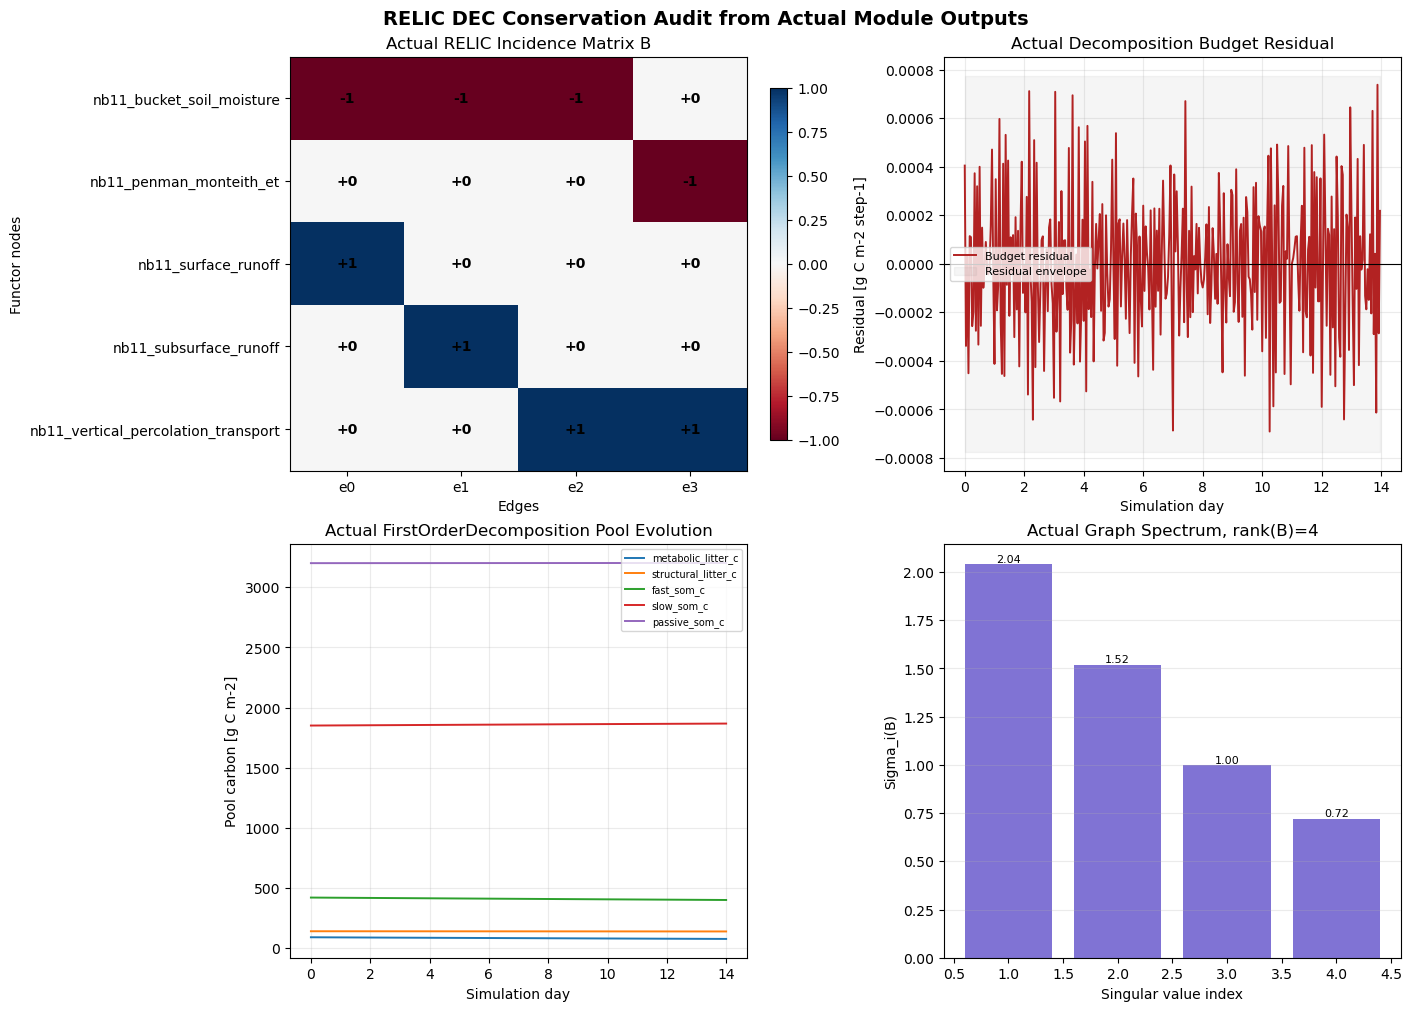

[OK] NB11 visualization generated from actual RELIC graph structure and decomposition budget outputs.


In [11]:
# === NB11: Actual RELIC Conservation Audit Visualization ===
# References:
# - DEC incidence operators for process graphs.
# - FirstOrderDecomposition conservation contract in RELIC pedosphere.
# Mathematical expression:
# - residual_n = Delta_S_n - (litter_input_n - R_hetero,n) * dt
# - B in {-1,0,+1}^{n_nodes x n_edges}
# Units: Graph entries are dimensionless; carbon diagnostics retain the stated areal units.
# Domain/constraints: Explicit finite inputs and declared graph; no physical claim from dependency topology alone.
# Sign convention: Incidence is incoming minus outgoing; clip loss is requested minus committed.
# Parameter meanings:
# - residual_history: per-step conservation residual [g C m-2 step-1]
# - total_storage_history: decomposition pool storage history [g C m-2]
# - B: incidence matrix of the actual RELIC functor graph

import matplotlib.pyplot as plt
from IPython.display import display
import torch

assert B.shape[0] > 0 and B.shape[1] > 0, 'Actual RELIC dependency graph must contain at least one edge for DEC visualization.'

print('=== Actual RELIC Conservation Visualization ===')
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)

axt = axes[0, 0]
im = axt.imshow(B.to(torch.float32).tolist(), cmap='RdBu', vmin=-1, vmax=1, aspect='auto')
for i in range(B.shape[0]):
    for j in range(B.shape[1]):
        axt.text(j, i, f'{int(B[i, j].item()):+d}', ha='center', va='center', fontsize=10, fontweight='bold')
axt.set_xlabel('Edges')
axt.set_ylabel('Functor nodes')
axt.set_title('Actual RELIC Incidence Matrix B')
axt.set_xticks(range(B.shape[1]))
axt.set_xticklabels([f'e{j}' for j in range(B.shape[1])])
axt.set_yticks(range(B.shape[0]))
axt.set_yticklabels(node_ids)
fig.colorbar(im, ax=axt, shrink=0.85)

axr = axes[0, 1]
time_days = torch.arange(residual_history.numel(), dtype=torch.float32) * dt / 86400.0
axr.plot(time_days.tolist(), residual_history.tolist(), color='firebrick', linewidth=1.4, label='Budget residual')
axr.axhline(0.0, color='black', linewidth=0.8)
residual_tol = tensor_to_float(torch.max(torch.abs(residual_history))) * 1.05
axr.fill_between(time_days.tolist(), [-residual_tol] * residual_history.numel(), [residual_tol] * residual_history.numel(), color='gray', alpha=0.08, label='Residual envelope')
axr.set_xlabel('Simulation day')
axr.set_ylabel('Residual [g C m-2 step-1]')
axr.set_title('Actual Decomposition Budget Residual')
axr.legend(fontsize=8)
axr.grid(True, alpha=0.25)

axp = axes[1, 0]
for pool_name, color in [
    ('metabolic_litter_c', '#4C72B0'),
    ('structural_litter_c', '#55A868'),
    ('fast_som_c', '#C44E52'),
    ('slow_som_c', '#8172B2'),
    ('passive_som_c', '#CCB974'),
]:
    pool_time_days = torch.arange(pool_history[pool_name].numel(), dtype=torch.float32) * dt / 86400.0
    axp.plot(pool_time_days.tolist(), pool_history[pool_name].tolist(), linewidth=1.4, label=pool_name)
axp.set_xlabel('Simulation day')
axp.set_ylabel('Pool carbon [g C m-2]')
axp.set_title('Actual FirstOrderDecomposition Pool Evolution')
axp.legend(fontsize=7)
axp.grid(True, alpha=0.25)

axs = axes[1, 1]
B_float = B.to(torch.float64)
_, singular_values, _ = torch.linalg.svd(B_float)
rank_B_local = int(torch.sum(singular_values > 1.0e-10).item())
axs.bar(range(1, singular_values.numel() + 1), singular_values.tolist(), color='slateblue', alpha=0.85)
axs.set_xlabel('Singular value index')
axs.set_ylabel('Sigma_i(B)')
axs.set_title(f'Actual Graph Spectrum, rank(B)={rank_B_local}')
for idx, sigma in enumerate(singular_values.tolist(), start=1):
    axs.text(idx, sigma, f'{sigma:.2f}', ha='center', va='bottom', fontsize=8)
axs.grid(True, axis='y', alpha=0.25)

plt.suptitle('RELIC DEC Conservation Audit from Actual Module Outputs', fontsize=14, fontweight='bold')
display(plt.gcf())
plt.close(plt.gcf())
print('[OK] NB11 visualization generated from actual RELIC graph structure and decomposition budget outputs.')

In [12]:
# ---------------------------------------------------------------
# References:
#   RELIC coertheory.md, Sec.0.3-0.4: Engineering Constraint Chain
#   RELIC StateManager._clip_loss_diagnostics
# Mathematical expression:
#   Conservation residual with clipping:
#   r_clip = sum(abs(clip_loss_i)) / sum(abs(total_increment_i))
#   If r_clip > threshold, the model has a process imbalance
# Units: Graph entries are dimensionless; carbon diagnostics retain the stated areal units.
# Domain/constraints: Explicit finite inputs and declared graph; no physical claim from dependency topology alone.
# Sign convention: Incidence is incoming minus outgoing; clip loss is requested minus committed.
# Parameter meanings:
#   r_clip: fractional conservation loss due to clipping
#   threshold: alarm level (e.g., 1% of total flux)
# ---------------------------------------------------------------

# Demonstrate clip_loss as part of the three-layer constraint chain:
# Structure (sigma) -> Budget (residual) -> Stability (CFL)

# From NB14: structural invariants ensure topological consistency
# Here: clip_loss connects to the BUDGET layer

threshold = 0.01  # 1% of total flux

# Case 1: Healthy model (no clipping)
x_healthy = torch.tensor([150.0, 80.0, 300.0])
dx_healthy = torch.tensor([3.0, -1.0, -2.0])  # balanced
x_new, clip = bounded_commit_probe(x_healthy, dx_healthy)
r_clip = float(clip.abs().sum()) / max(float(dx_healthy.abs().sum()), 1e-10)

print("=== Clip Loss as Conservation Diagnostic ===")
print()
print(f"Case 1 (healthy): r_clip = {r_clip:.6f} ({r_clip*100:.4f}%)")
print(f"  Status: {'[OK]' if r_clip < threshold else '[ALARM]'}")
print()

# Case 2: Broken model (extreme clipping)
dx_broken = torch.tensor([-200.0, 600.0, 100.0])  # clearly wrong
x_new2, clip2 = bounded_commit_probe(x_healthy, dx_broken)
r_clip2 = float(clip2.abs().sum()) / max(float(dx_broken.abs().sum()), 1e-10)

print(f"Case 2 (broken): r_clip = {r_clip2:.6f} ({r_clip2*100:.2f}%)")
print(f"  Status: {'[OK]' if r_clip2 < threshold else '[ALARM]'}")
print(f"  clip_loss details: {clip2.tolist()}")
print()

print("KEY INSIGHT: clip_loss is the BUDGET-layer alarm.")
print("  Structure layer: sigma(G) catches topology errors (NB14)")
print("  Budget layer: clip_loss catches process magnitude errors")
print("  Stability layer: CFL catches timestep errors")
print()
print("In RELIC, call StateManager.get_diagnostics() after each commit")
print("to retrieve clip_loss values for the most recent commit only.")


=== Clip Loss as Conservation Diagnostic ===

Case 1 (healthy): r_clip = 0.000000 (0.0000%)
  Status: [OK]

Case 2 (broken): r_clip = 0.255556 (25.56%)
  Status: [ALARM]
  clip_loss details: [-50.0, 180.0, 0.0]

KEY INSIGHT: clip_loss is the BUDGET-layer alarm.
  Structure layer: sigma(G) catches topology errors (NB14)
  Budget layer: clip_loss catches process magnitude errors
  Stability layer: CFL catches timestep errors

In RELIC, call StateManager.get_diagnostics() after each commit
to retrieve clip_loss values for the most recent commit only.


## Transactional Updates in the Constraint Chain

The transactional state update operator $\mathcal{U}_{\Delta t}$ is one of three diagnostic layers:

| Layer | What it checks | RELIC diagnostic |
|---|---|---|
| **Structure** ($\sigma$) | Topology is correct | `get_topology_signature()` (NB14) |
| **Clipping** ($r_{\text{clip}}$) | Amount changed by configured bounds; not a complete budget | `clip_loss` in `get_diagnostics()` (most recent commit only) |
| **Step size** ($E_n$ heuristic) | Committed-state-change magnitude stays near tolerance; not a CFL or stability check | private `_compute_error_norm()` in `relic.core.simulator.execution_loop` (NB12) |

### Checked Conditions

$$\sigma(\mathcal{G}) = \text{const} \quad \wedge \quad r_{\text{clip}} < \epsilon \quad \wedge \quad E_n \le 1$$

$E_n$ is the value of `_compute_error_norm`. The simulator evaluates it on the fast-group updates only when `adaptive_dt_enabled` is true (default false):

$$E_n = \sqrt{\frac{1}{m}\sum_{k=1}^{m} \operatorname{mean}\left[\left(\frac{u_k}{\mathrm{atol} + \mathrm{rtol}\,\lvert x_k \rvert}\right)^2\right]}$$

Written update names first map to actual StateManager targets (`delta_x` to `x`); each target is counted once before monitor filtering and pre/post-state lookup, without making SCM read aliases writable. Here $x_k$ is monitored variable $k$ before the fast group; $u_k=x'_k-x_k$ uses the value $x'_k$ that StateManager actually committed, including rate integration over the true interval, clipping and distributed reduction; the mean runs over the tensor elements; atol and rtol are `adaptive_atol` and `adaptive_rtol` (defaults $10^{-6}$ and $10^{-3}$); $m$ is the number of monitored variables, and $E_n = 0$ when $m = 0$. $E_n$ is a control heuristic over committed state changes, not a CFL, Richardson or local-truncation-error estimate. When $E_n > 1$ and $\Delta t > \Delta t_{\min}$ the step is rolled back and retried once over a shorter interval; the retry is accepted without a second check, so an accepted step can still have $E_n > 1$. The step-size layer therefore gives no stability guarantee.

`relic.core.simulator` itself evaluates no CFL condition. The canonical `transport.advection` and `transport.diffusion` operators compute their own stability numbers when `check_cfl` or `check_stability` is on (default true): the outflow Courant number $C_{\text{out},i} = \Delta t \sum_k \left[\max(u_{k,i+1/2}, 0) - \min(u_{k,i-1/2}, 0)\right] / \Delta x_k$ and the diffusion number $s_i = \sum_k K_{k,i}\,\Delta t / \Delta x_k^2$. With the explicit Euler integrator (`transport.numerical.time_integration_method`, default `euler`) they raise `ValueError` when the maximum exceeds `transport.numerical.cfl_advection_max` (1.0) or `transport.numerical.cfl_diffusion_max` (0.5, scaled by 2/3 for Dirichlet boundaries). During a run this `ValueError` becomes the cause of a `RuntimeError` raised by the group execution; the step is rolled back and the run stops, with no retry at a shorter $\Delta t$. `LinearAdvection` reports the maximum Courant number as `diagnostics.cfl_number` and `FickianDiffusion` the maximum diffusion number as `diagnostics.diffusion_stability`. `compute_cfl_number` and `compute_diffusion_stability` (`relic.computation.operators.functional`, re-exported by `relic.scientific.transport`) are standalone helpers that these two operators do not call. When the first two conditions hold, the run keeps a constant topology and a small clipping residual; numerical stability is a separate check. The transactional update with `clip_loss` monitoring is the *budget layer* of this chain.


---
## Part 3: Dependency Graph Topology & Conservation Diagnostics

> **Reference:** `docs/source/theory/spatiotemporal_scale_topology.md` Sec 4.3-5.1
>
> This section demonstrates the topological properties of the dependency
> graph, Betti number analysis, and the Noether invariant audit.


### 3.1 DAG Topology: Topological Sort & Betti Numbers

The dependency graph $\mathcal{G} = (\mathcal{V}, \mathcal{E})$ is a DAG where:
- $\mathcal{V}$ = set of Functors
- $\mathcal{E}$ = edges from producer to consumer

**Topological sort** $\sigma$ yields a valid execution ordering.

**Betti numbers** characterize graph topology:
- $\beta_0 = $ number of connected components (should be 1 for fully coupled system)
- $\beta_1 = |\mathcal{E}| - |\mathcal{V}| + \beta_0$ = number of independent cycles

Here $\beta_1$ is the cycle rank of the underlying undirected graph. A DAG can
have positive $\beta_1$; it does not prove directed feedback or require
operator splitting. Actual directed cycles are rejected by the dependency resolver.


=== Actual RELIC DAG Topology Analysis ===
|V| (functors): 5
|E| (edges):    4
beta_0 (components): 1
beta_1 (cycles):     0
Connected components: [['nb11_bucket_soil_moisture', 'nb11_penman_monteith_et', 'nb11_subsurface_runoff', 'nb11_surface_runoff', 'nb11_vertical_percolation_transport']]
[OK] Actual RELIC fast-process graph is acyclic.


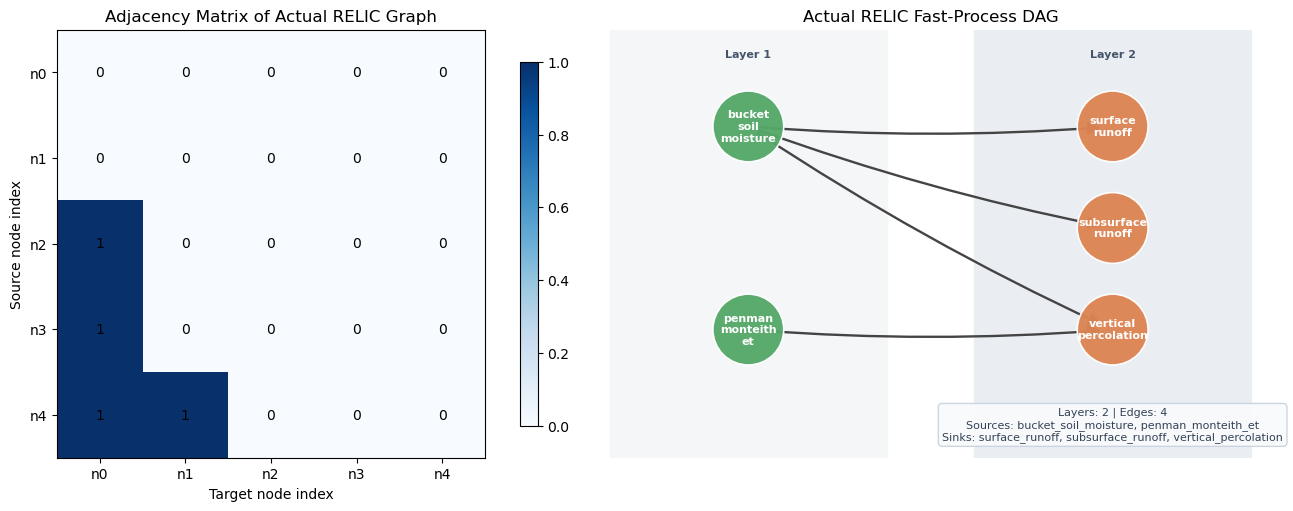

[OK] Actual RELIC topology figure generated.


In [13]:
# === Actual RELIC DAG Topology Analysis ===
# References:
# - RELIC dependency graph semantics for producer-consumer relations.
# - Graph-theoretic identity beta_1 = |E| - |V| + beta_0.
# Mathematical expression:
# - beta_1 = m - n + kappa
# Units: Graph entries are dimensionless; carbon diagnostics retain the stated areal units.
# Domain/constraints: Explicit finite inputs and declared graph; no physical claim from dependency topology alone.
# Sign convention: Incidence is incoming minus outgoing; clip loss is requested minus committed.
# Parameter meanings:
# - node_ids: actual functor nodes from DependencyGraphResolver
# - resolver.edges: directed dependency edges in the actual graph

import matplotlib.pyplot as plt
from IPython.display import display
import networkx as nx
import torch

functors = node_ids
actual_edges = [(edge.target, edge.source) for edge in resolver.edges]
V = len(functors)
E = len(actual_edges)

adjacency = torch.zeros((V, V), dtype=torch.float32)
for edge in resolver.edges:
    src_idx = node_idx[edge.source]
    tgt_idx = node_idx[edge.target]
    adjacency[src_idx, tgt_idx] = 1.0

visited = set()
components = []
adj_undirected_actual = {name: set() for name in functors}
for src, dst in actual_edges:
    adj_undirected_actual[src].add(dst)
    adj_undirected_actual[dst].add(src)
for start in functors:
    if start in visited:
        continue
    comp = set()
    stack = [start]
    while stack:
        current = stack.pop()
        if current in visited:
            continue
        visited.add(current)
        comp.add(current)
        stack.extend(adj_undirected_actual[current] - visited)
    components.append(comp)

beta_0_actual = len(components)
beta_1_actual = E - V + beta_0_actual

print('=== Actual RELIC DAG Topology Analysis ===')
print(f'|V| (functors): {V}')
print(f'|E| (edges):    {E}')
print(f'beta_0 (components): {beta_0_actual}')
print(f'beta_1 (cycles):     {beta_1_actual}')
print(f'Connected components: {[sorted(component) for component in components]}')
assert beta_1_actual == 0, f'Expected a DAG with beta_1=0, got {beta_1_actual}'
print('[OK] Actual RELIC fast-process graph is acyclic.')

fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)

ima = axes[0].imshow(adjacency.tolist(), cmap='Blues', vmin=0.0, vmax=1.0)
axes[0].set_title('Adjacency Matrix of Actual RELIC Graph')
axes[0].set_xlabel('Target node index')
axes[0].set_ylabel('Source node index')
axes[0].set_xticks(range(V))
axes[0].set_xticklabels([f'n{i}' for i in range(V)])
axes[0].set_yticks(range(V))
axes[0].set_yticklabels([f'n{i}' for i in range(V)])
for i in range(V):
    for j in range(V):
        axes[0].text(j, i, int(adjacency[i, j].item()), ha='center', va='center', fontsize=10)
fig.colorbar(ima, ax=axes[0], shrink=0.85)

G = nx.DiGraph()
G.add_nodes_from(functors)
G.add_edges_from(actual_edges)
assert nx.is_directed_acyclic_graph(G), 'Declared dependency graph must be a DAG.'
generations = list(nx.topological_generations(G))
layer_lookup = {}
positions = {}
for layer_index, nodes_in_layer in enumerate(generations):
    if len(nodes_in_layer) == 1:
        y_coords = [0.0]
    else:
        y_coords = torch.linspace(0.42, -0.42, steps=len(nodes_in_layer)).tolist()
    for node_name, y_coord in zip(nodes_in_layer, y_coords):
        layer_lookup[node_name] = layer_index
        positions[node_name] = (float(layer_index), float(y_coord))
nx.set_node_attributes(G, layer_lookup, 'layer')
wrapped_labels = {
    node_name: node_name.replace('nb11_', '').replace('_transport', '').replace('_', chr(10))
    for node_name in G.nodes()
}
source_nodes = [
    node_name.replace('nb11_', '').replace('_transport', '')
    for node_name in G.nodes()
    if G.in_degree(node_name) == 0
]
sink_nodes = [
    node_name.replace('nb11_', '').replace('_transport', '')
    for node_name in G.nodes()
    if G.out_degree(node_name) == 0
]
node_colors = []
for node_name in G.nodes():
    if G.in_degree(node_name) == 0 and G.out_degree(node_name) > 0:
        node_colors.append('#55A868')
    elif G.in_degree(node_name) > 0 and G.out_degree(node_name) == 0:
        node_colors.append('#DD8452')
    else:
        node_colors.append('#4C72B0')
for layer_index in range(len(generations)):
    band_color = '#F4F6F8' if layer_index % 2 == 0 else '#E9EEF3'
    axes[1].axvspan(layer_index - 0.38, layer_index + 0.38, color=band_color, alpha=0.95, zorder=0)
    axes[1].text(float(layer_index), 0.72, f'Layer {layer_index + 1}', ha='center', va='center', fontsize=8, fontweight='bold', color='#44546A')
nx.draw_networkx_nodes(
    G,
    positions,
    ax=axes[1],
    node_color=node_colors,
    node_size=2600,
    alpha=0.96,
    linewidths=1.2,
    edgecolors='white',
)
nx.draw_networkx_edges(
    G,
    positions,
    ax=axes[1],
    arrows=True,
    arrowsize=18,
    width=1.7,
    edge_color='#444444',
    connectionstyle='arc3,rad=0.04',
)
nx.draw_networkx_labels(
    G,
    positions,
    ax=axes[1],
    labels=wrapped_labels,
    font_size=8,
    font_color='white',
    font_weight='bold',
)
summary_lines = [
    f'Layers: {len(generations)} | Edges: {G.number_of_edges()}',
    'Sources: ' + ', '.join(source_nodes),
    'Sinks: ' + ', '.join(sink_nodes),
]
axes[1].text(
    1.0,
    -0.74,
    chr(10).join(summary_lines),
    ha='center',
    va='top',
    fontsize=8,
    color='#334155',
    bbox={'boxstyle': 'round,pad=0.35', 'facecolor': '#F8FAFC', 'edgecolor': '#CBD5E1', 'alpha': 0.98},
)
axes[1].set_xlim(-0.45, max(0.55, len(generations) - 0.55))
axes[1].set_ylim(-0.95, 0.82)
axes[1].set_title('Actual RELIC Fast-Process DAG')
axes[1].axis('off')

display(plt.gcf())
plt.close(plt.gcf())
print('[OK] Actual RELIC topology figure generated.')

### 3.2 Cumulative Carbon Budget Drift Monitoring

This section monitors a declared carbon ledger. No Lagrangian symmetry is
constructed, so the plotted quantity is cumulative budget drift, not a new
Noether-theorem verification.

For this discrete carbon ledger, the **cumulative budget drift** is:

$$\Delta Q_n = Q(S_n) - Q(S_0) - \sum_{k=0}^{n-1} \Phi_k^{\text{ext}} \cdot \Delta t_k$$

where:
- $Q(S_n)$ = conserved quantity at step $n$ (e.g., total carbon)
- $\Phi_k^{\text{ext}}$ = external forcing fluxes at step $k$
- Perfect conservation implies $\Delta Q_n = 0$ for all $n$

**Illustrative display thresholds, not framework acceptance criteria:**
- $|\Delta Q_n / Q_0| < 10^{-8}$: EXCELLENT
- $10^{-8} \le |\Delta Q_n / Q_0| < 10^{-6}$: ACCEPTABLE
- $|\Delta Q_n / Q_0| \ge 10^{-6}$: WARNING; investigate conservation closure


=== Cumulative Carbon Budget Drift from Actual RELIC Decomposition Run ===
Q_0               = 5700.000000 g C m-2
Q_final           = 5682.278320 g C m-2
Max |drift|       = 1.963615e-03 g C m-2
Relative drift    = 3.444939e-07
Status: ACCEPTABLE


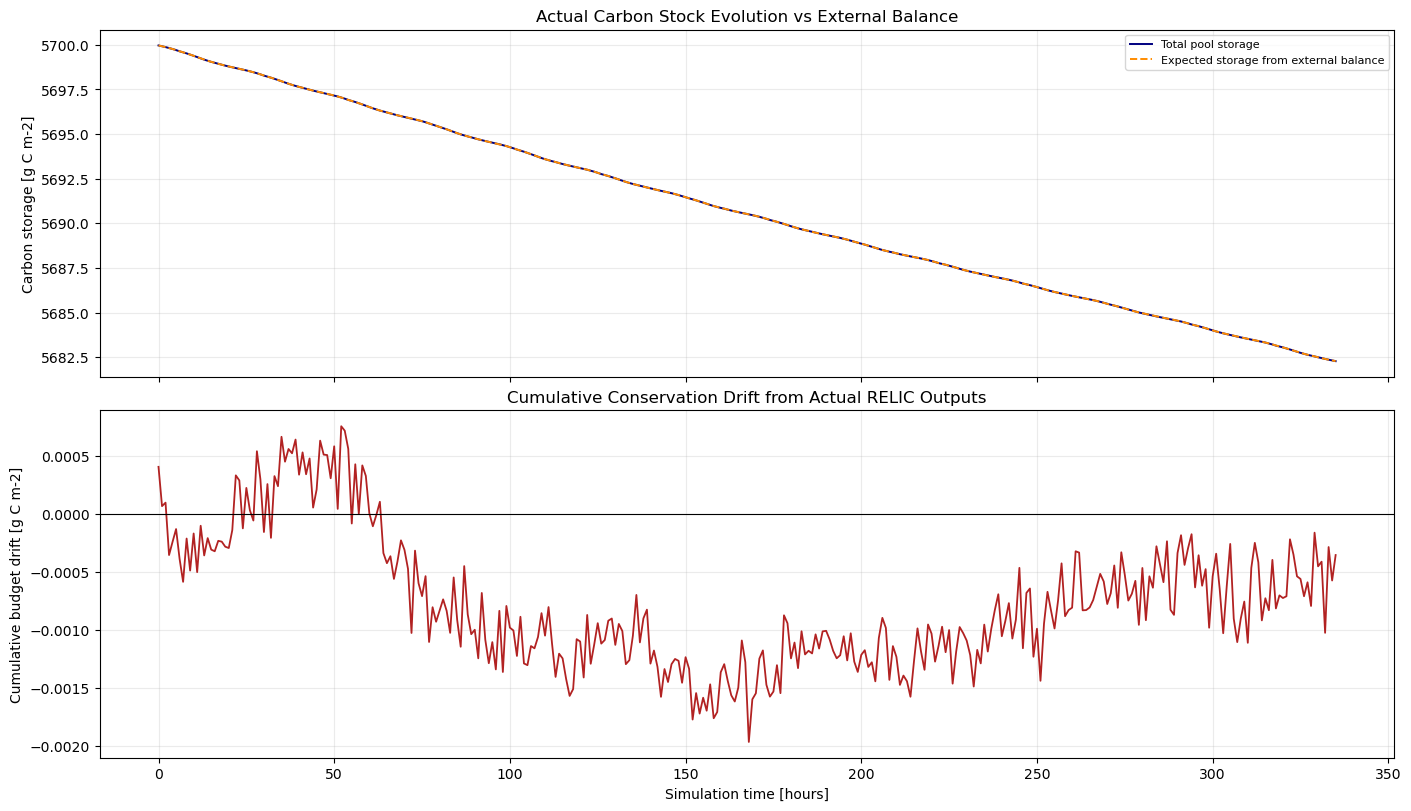

[OK] Actual cumulative carbon-budget drift visualization generated.


In [14]:
from IPython.display import display
# === Cumulative Carbon Budget Drift from Actual RELIC Outputs ===
# References:
# - Noether (1918) symmetry and conservation laws.
# - FirstOrderDecomposition conservation closure in RELIC pedosphere.
# Mathematical expression:
# - drift_n = Q_n - Q_0 - sum_{k<=n} (litter_input_k - R_hetero,k) * dt
# Units: Graph entries are dimensionless; carbon diagnostics retain the stated areal units.
# Domain/constraints: Explicit finite inputs and declared graph; no physical claim from dependency topology alone.
# Sign convention: Incidence is incoming minus outgoing; clip loss is requested minus committed.
# Parameter meanings:
# - Q_n: total decomposition-pool carbon storage [g C m-2]
# - litter_input_history: external carbon forcing [g C m-2 s-1]
# - heterotrophic_respiration_history: external carbon loss [g C m-2 s-1]

cumulative_external = torch.cumsum((litter_input_history - heterotrophic_respiration_history) * dt, dim=0)
noether_drift_history = total_storage_history[1:] - total_storage_history[0] - cumulative_external
max_abs_drift = torch.max(torch.abs(noether_drift_history))
relative_drift = max_abs_drift / torch.clamp(total_storage_history[0], min=torch.tensor(1.0, dtype=torch.float32))

time_hours = (torch.arange(noether_drift_history.numel(), dtype=torch.float32) * dt / 3600.0)

print('=== Cumulative Carbon Budget Drift from Actual RELIC Decomposition Run ===')
print(f'Q_0               = {tensor_to_float(total_storage_history[0]):.6f} g C m-2')
print(f'Q_final           = {tensor_to_float(total_storage_history[-1]):.6f} g C m-2')
print(f'Max |drift|       = {tensor_to_float(max_abs_drift):.6e} g C m-2')
print(f'Relative drift    = {tensor_to_float(relative_drift):.6e}')
if tensor_to_float(relative_drift) < 1.0e-8:
    print('Status: EXCELLENT')
elif tensor_to_float(relative_drift) < 1.0e-6:
    print('Status: ACCEPTABLE')
else:
    print('Status: WARNING - investigate conservation closure')

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, constrained_layout=True)
axes[0].plot(time_hours.tolist(), total_storage_history[1:].tolist(), color='navy', linewidth=1.4, label='Total pool storage')
axes[0].plot(time_hours.tolist(), (total_storage_history[0] + cumulative_external).tolist(), color='darkorange', linewidth=1.4, linestyle='--', label='Expected storage from external balance')
axes[0].set_ylabel('Carbon storage [g C m-2]')
axes[0].set_title('Actual Carbon Stock Evolution vs External Balance')
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.25)

axes[1].plot(time_hours.tolist(), noether_drift_history.tolist(), color='firebrick', linewidth=1.3)
axes[1].axhline(0.0, color='black', linewidth=0.8)
axes[1].set_ylabel('Cumulative budget drift [g C m-2]')
axes[1].set_xlabel('Simulation time [hours]')
axes[1].set_title('Cumulative Conservation Drift from Actual RELIC Outputs')
axes[1].grid(True, alpha=0.25)

display(plt.gcf())
plt.close(plt.gcf())
print('[OK] Actual cumulative carbon-budget drift visualization generated.')

## Summary and Evidence Boundary

- Incidence columns sum to zero on the explicitly declared dependency graph.
- Its underlying graph is a five-node tree, and the measured kernel dimension
  equals its undirected cycle rank. This does not certify physical conservation.
- Actual decomposition outputs are checked against their external carbon budget.
- The real StateManager demonstrates typed amount commits and signed clip loss.
- Cumulative carbon drift is a ledger diagnostic, not proof of a continuous symmetry.
- Adaptive control measures committed changes; numerical stability and full-system
  scientific validation remain separate requirements.
